# Capítulo 4 · Métodos basados en modelos

**Lectura:** pp. 83–120; §§4.1–4.5. [Capítulo original](https://arxiv.org/html/2412.05265v5#Ch4).

**Idea central:** aprender cómo funciona el entorno permite convertir cómputo en experiencia imaginada; la utilidad de esa experiencia depende de la fidelidad del modelo.

## Resumen

§4.1 plantea el intercambio fundamental: una interacción real puede ser costosa, mientras que simularla puede ser barato. Aprender un modelo de transiciones y recompensas permite buscar acciones o entrenar políticas dentro del modelo. Sin embargo, una política puede descubrir y explotar errores de predicción. Por eso la recogida de datos, el ajuste del modelo y la mejora de la política suelen alternarse.

§4.2 estudia la planificación en el momento de decidir. La búsqueda hacia delante considera futuros posibles; branch and bound y métodos heurísticos reducen la exploración del árbol. MCTS asigna simulaciones de forma selectiva, combinando estimaciones de valor y exploración. AlphaZero usa reglas conocidas; MuZero aprende representaciones y una dinámica orientada a recompensas, valores y políticas.

El control predictivo, MPC, optimiza una secuencia de acciones, ejecuta la primera y vuelve a planificar tras observar el nuevo estado. La secuencia interna es de lazo abierto, aunque el controlador completo incorpora realimentación al replanificar. En entornos estocásticos, una política contingente puede superar a cualquier secuencia fija porque anticipa cómo aprovechar futuras observaciones. LQR, CEM, random shooting, MPPI y métodos con procesos gaussianos ofrecen distintas formas de resolver o aproximar la optimización.

§4.3 cambia el momento de usar el modelo: la planificación en segundo plano produce datos imaginados que mejoran una política reactiva. Dyna combina actualizaciones a partir de datos reales y simulados. La perspectiva de juegos y optimización a dos niveles ayuda a pensar cómo coordinar el modelo y la política. Aquí “planificación offline” significa fuera del instante de decisión; no implica necesariamente el conjunto fijo de datos de offline RL del capítulo 7.

§4.4 pregunta qué debería predecir el modelo. Reconstruir observaciones completas proporciona una señal rica, pero puede gastar capacidad en detalles irrelevantes. Dreamer aprende una representación dinámica y entrena en imaginación; IRIS usa representaciones discretas y modelos autorregresivos. Otras familias predicen recompensas, valores, políticas o representaciones futuras, buscando preservar información útil para decidir.

Aprender representaciones por autopredicción introduce el riesgo de colapso: mapear todas las observaciones al mismo vector hace la predicción fácil e inútil. Objetivos auxiliares, redes objetivo y regularizadores intentan evitarlo; sus garantías dependen del caso. JEPA, BYOL y TD-MPC muestran distintas combinaciones. El capítulo también aborda error acumulado, rollouts cortos, incertidumbre y la posibilidad de alternar métodos con y sin modelo.

§4.5 estudia predicciones a más de un paso. Las funciones de valor generalizadas predicen señales distintas de la recompensa. Las representaciones y características sucesoras acumulan ocupaciones o características futuras bajo una política. Así puede reevaluarse rápidamente una recompensa nueva, siempre respetando la dependencia respecto a la política y la representación. La mejora generalizada de políticas reutiliza una biblioteca de habilidades; las medidas sucesoras conectan predicción y muestreo de futuros.

## Ecuación esencial

Si la recompensa es lineal en características de transición,

$$
r(s,a,s')=\phi(s,a,s')^\top w,
\qquad
\psi^\pi(s,a)=
\mathbb{E}_\pi\left[\sum_{t\geq0}\gamma^t\phi(s_t,a_t,s_{t+1})\mid s_0=s,a_0=a\right],
$$

entonces

$$
Q^\pi_w(s,a)=\psi^\pi(s,a)^\top w.
$$

Cambiar $w$ permite evaluar otra recompensa sin reaprender $\psi^\pi$. Si cambia la dinámica o queremos una política distinta, la reutilización necesita trabajo adicional.

## Experimento 4 · Dyna-Q

**Pregunta:** ¿cuánto se gana en aprendizaje por interacción real cuando reutilizamos un modelo aprendido?

Una cadena determinista tiene nueve estados; los extremos son terminales. El agente empieza en 1 y recibe 1 al llegar a 8. Las demás recompensas son cero. Se comparan 0, 5 y 20 actualizaciones imaginadas por transición real, con el mismo presupuesto de 1.600 transiciones y 20 semillas.

Cada transición observada actualiza Q y una tabla del modelo. La planificación muestrea solo pares estado-acción ya observados y aplica otra actualización de Bellman. No se entrega el modelo real al aprendiz. En este entorno determinista, almacenar una transición basta para conocer ese par.

~~~bash
uv run python -m experimentos.ejecutar --capitulo 4
~~~

**Métricas:** error frente a $Q^*$ y metas alcanzadas durante el entrenamiento. También se registran las actualizaciones totales: 1.600, 9.600 y 33.600.

**Qué observar:** la planificación propaga antes la información de la meta y reduce el error con menos datos reales. En los resultados guardados, 5 y 20 pasos alcanzan prácticamente el mismo error final; veinte pasos no aportan una mejora proporcional a su coste.

**Modificación:** compara a igual número total de actualizaciones, no solo a igual cantidad de datos. Como extensión de implementación, añade dinámica estocástica: una tabla que recuerde únicamente la última transición ya no será un modelo fiel de su distribución.

**Límite:** aquí el modelo observado es exacto y no existe error acumulado de una red. El experimento no demuestra que planificar más siempre sea mejor ni reproduce Dreamer o MuZero.



## Para el grupo

1. ¿Cuándo vale más una transición real que miles de transiciones imaginadas?
2. ¿Por qué predecir bien los píxeles puede ser insuficiente para actuar bien?
3. ¿Qué diferencia hay entre cambiar la recompensa y cambiar la dinámica al reutilizar características sucesoras?

**Conexión:** aprender un modelo y una política a la vez anticipa los problemas de interacción y no estacionariedad del capítulo 5.


## Preparar la ejecución

Ejecuta todas las celdas en orden. El módulo contiene la implementación completa; la siguiente celda muestra su código. Cambia SEMILLA y REPLICAS para repetir. Los resultados del cuaderno se guardan en una carpeta separada.

In [1]:
from pathlib import Path
import sys
import json
import inspect
import subprocess
import importlib
from IPython.display import display, Image, Code

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(p for p in candidates if (p / "experimentos" / "ejecutar.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
CAPITULO = 4
SEMILLA = 2026
REPLICAS = 20
SALIDA = ROOT / "resultados" / "cuadernos"
modulo = importlib.import_module(f"experimentos.cap{CAPITULO:02d}")
display(Code(inspect.getsource(modulo), language="python"))

"""Cap. 4: Dyna-Q, coste de planificación y eficiencia en datos reales."""
import numpy as np
import matplotlib.pyplot as plt
from .comun import (cadena, iteracion_valor, greedy_aleatorio, guardar, curva,
                    filas_finales, resumen_muestra)

def entrenar(seed, planning, pasos=1600):
    rng_act = np.random.default_rng(seed)
    rng_plan = np.random.default_rng(seed+100000)
    p, r = cadena(n=9, slip=0, coste=0)
    _, qstar = iteracion_valor(p, r)
    q = np.zeros((9, 2))
    model = {}
    keys = []
    s, goals = 1, 0
    errors, successes = [], []
    for t in range(pasos+1):
        if t % 20 == 0:
            errors.append(np.sqrt(np.mean((q[1:-1]-qstar[1:-1])**2)))
            successes.append(goals)
        if t == pasos:
            break
        a = int(rng_act.integers(2)) if rng_act.random() < .2 else greedy_aleatorio(q[s], rng_act)
        ns = s+(1 if a else -1)
        reward, done = float(ns == 8), ns in (0, 8)
        q[s, a] += .2*(reward+.95*(not done)*q[ns].max()-q[s, a])
        if (s, a) not in model:
            keys.append((s, a))
        model[s, a] = (ns, reward, done)
        for _ in range(planning):
            ms, ma = keys[int(rng_plan.integers(len(keys)))]
            mn, mr, md = model[ms, ma]
            q[ms, ma] += .2*(mr+.95*(not md)*q[mn].max()-q[ms, ma])
        goals += ns == 8
        s = 1 if done else ns
    return np.array(errors), np.array(successes)

def ejecutar(out, seed=2026, replicas=20):
    arrays, rows, metrics = {}, [], {"pasos_reales": 1600, "epsilon": .2, "alpha": .2, "gamma": .95}
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    for n in [0, 5, 20]:
        data = [entrenar(seed+k, n) for k in range(replicas)]
        err, goals = np.array([x[0] for x in data]), np.array([x[1] for x in data])
        name = f"{n} pasos de planificación"
        x = np.arange(err.shape[1])*20
        curva(ax[0], x, err, name)
        curva(ax[1], x, goals, name)
        arrays[f"rmse_{n}"], arrays[f"metas_{n}"] = err, goals
        rows += filas_finales(name, err[:, -1])
        metrics[str(n)] = {"rmse_final": resumen_muestra(err[:, -1]),
                          "metas_alcanzadas": resumen_muestra(goals[:, -1]),
                          "backups_totales_por_replica": 1600*(1+n)}
    ax[0].set(xlabel="Transiciones reales", ylabel="RMSE frente a Q*", title="Propagar información mediante el modelo")
    ax[1].set(xlabel="Transiciones reales", ylabel="Metas acumuladas durante entrenamiento", title="Más planificación requiere más cómputo")
    ax[0].legend()
    return guardar(out, arrays, rows, metrics, fig)

## Ejecutar y registrar

El comando utiliza el mismo Python del kernel y conserva parámetros y hashes en su manifiesto. No necesita servicios externos.

In [2]:
command = [sys.executable, "-m", "experimentos.ejecutar",
           "--capitulo", str(CAPITULO), "--semilla", str(SEMILLA),
           "--replicas", str(REPLICAS), "--salida", str(SALIDA)]
completed = subprocess.run(command, cwd=ROOT, capture_output=True, text=True, check=True)
print(completed.stdout)
carpeta = SALIDA / f"cap{CAPITULO:02d}"

Capítulo 4: completado en 2.56 s → /home/ialab/jairo_experiments/kevinMurphy/resultados/cuadernos/cap04



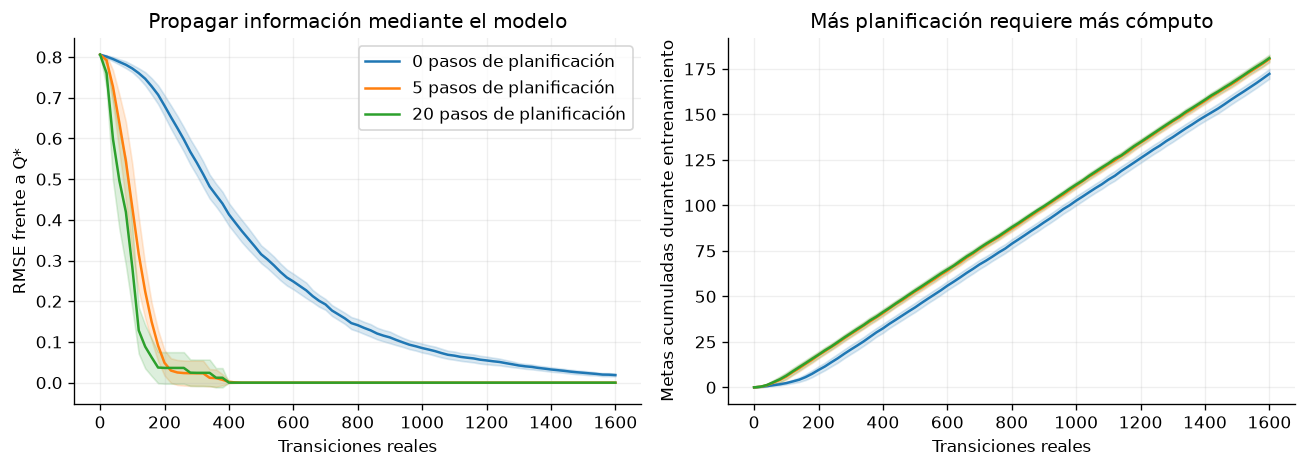

{
  "pasos_reales": 1600,
  "epsilon": 0.2,
  "alpha": 0.2,
  "gamma": 0.95,
  "0": {
    "rmse_final": {
      "media": 0.018604802381359024,
      "ic95_aprox_semianchura": 0.0031741218341718013
    },
    "metas_alcanzadas": {
      "media": 172.3,
      "ic95_aprox_semianchura": 2.687040398889298
    },
    "backups_totales_por_replica": 1600
  },
  "5": {
    "rmse_final": {
      "media": 9.619390824908336e-16,
      "ic95_aprox_semianchura": 8.867878071160629e-32
    },
    "metas_alcanzadas": {
      "media": 180.4,
      "ic95_aprox_semianchura": 1.88318967935284
    },
    "backups_totales_por_replica": 9600
  },
  "20": {
    "rmse_final": {
      "media": 9.619390824908336e-16,
      "ic95_aprox_semianchura": 8.867878071160629e-32
    },
    "metas_alcanzadas": {
      "media": 180.95,
      "ic95_aprox_semianchura": 1.8996253924337154
    },
    "backups_totales_por_replica": 33600
  }
}


In [3]:
display(Image(filename=str(carpeta / "figura.png")))
resumen = json.loads((carpeta / "resumen.json").read_text())
print(json.dumps(resumen, indent=2, ensure_ascii=False))

## Inspeccionar los datos

Las claves describen métricas; las dimensiones suelen ser réplica × instante, excepto los arrays auxiliares. Escribe una conclusión que apoyen los datos y una limitación. Prueba la modificación propuesta en el texto; antes de ejecutarla, predice su efecto.

In [4]:
import numpy as np
with np.load(carpeta / "datos.npz") as datos:
    for nombre in datos.files:
        print(nombre, datos[nombre].shape)

rmse_0 (20, 81)
metas_0 (20, 81)
rmse_5 (20, 81)
metas_5 (20, 81)
rmse_20 (20, 81)
metas_20 (20, 81)


## Tu variante

Anota aquí: hipótesis, parámetro cambiado, métrica, resultado y limitación. Para modificar la dinámica o el algoritmo, edita el módulo mostrado o copia su función a una celda y experimenta con ella.

Fuente: [Kevin P. Murphy, Reinforcement Learning: An Overview, v5](https://arxiv.org/abs/2412.05265v5), [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Resumen adaptado y experimento propio de esta guía.